# Sephora Skincare Analysis - CP1 Project
**Workflow:** 1. Loading, 2. Cleaning, 3. EDA, 4. Visualisation, 5. SQL cross-check, 6. Validation, 7. Machine learning


In [1]:
import glob
import os
import re
import sqlite3
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

# ---- the only place paths are set ----
DATA_DIR = r"C:\Users\Radhika Jawale\Downloads\archive (3)"   # folder with product_info.csv and reviews_*.csv
OUT_DIR = "outputs"                                            # cleaned CSVs, database and charts go here
CHART_DIR = os.path.join(OUT_DIR, "charts")
os.makedirs(CHART_DIR, exist_ok=True)


def banner(text):
    print("\n" + "=" * 90 + f"\n{text}\n" + "=" * 90)


def save_fig(name):
    plt.tight_layout()
    path = os.path.join(CHART_DIR, name)
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()
    print("saved:", os.path.abspath(path))

## 1. Data loading

In [2]:
prod_raw = pd.read_csv(os.path.join(DATA_DIR, "product_info.csv"))
print("Products:", prod_raw.shape)

files = sorted(glob.glob(os.path.join(DATA_DIR, "reviews_*.csv")))
assert files, f"No reviews_*.csv files found in {DATA_DIR}"
rev_raw = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
rev_raw = rev_raw.drop(columns=["Unnamed: 0"], errors="ignore")   # leftover index column
print(f"Reviews: {rev_raw.shape} from {len(files)} files")
print("Raw date sample:", rev_raw["submission_time"].head(3).tolist())

Products: (8494, 27)
Reviews: (1094411, 18) from 5 files
Raw date sample: ['01-02-2023', '21-03-2023', '21-03-2023']


## 2. Data cleaning

In [3]:
banner("2A. CLEAN PRODUCTS")
prod = prod_raw[prod_raw["primary_category"] == "Skincare"].copy()
n0 = len(prod)
prod = prod.drop_duplicates(subset="product_id")

# trim extra spaces in names
for c in ["product_name", "brand_name"]:
    prod[c] = prod[c].astype(str).str.split().str.join(" ")

# make number columns numeric
num_cols = ["price_usd", "sale_price_usd", "rating", "reviews", "loves_count"]
prod[num_cols] = prod[num_cols].apply(pd.to_numeric, errors="coerce")
prod = prod.rename(columns={"rating": "product_rating", "reviews": "product_reviews_count"})

# fill missing counts and categories
count_cols = ["product_reviews_count", "loves_count"]
prod[count_cols] = prod[count_cols].fillna(0).astype(int)
cat_cols = ["primary_category", "secondary_category", "tertiary_category"]
prod[cat_cols] = prod[cat_cols].fillna("Unknown")

# drop invalid prices
prod = prod[prod["price_usd"] > 0]

# new columns
ing = prod["ingredients"].fillna("")
prod["n_ingredients"] = np.where(ing.str.strip() == "", 0, ing.str.count(",") + 1)
prod["has_discount"] = prod["sale_price_usd"].notna().astype(int)
prod["price_band"] = pd.cut(
    prod["price_usd"], bins=[0, 25, 50, 100, np.inf], right=False,
    labels=["1: under 25", "2: 25-50", "3: 50-100", "4: 100+"],
).astype(str)

print(f"Products: {n0} skincare rows -> {len(prod)} after de-dup/price check")


2A. CLEAN PRODUCTS
Products: 2420 skincare rows -> 2420 after de-dup/price check


In [4]:
banner("2B. CLEAN REVIEWS")
rev = rev_raw[rev_raw["product_id"].isin(prod["product_id"])].copy()
n1 = len(rev)
rev = rev.drop_duplicates(subset=["author_id", "product_id", "submission_time", "review_text"])
n2 = len(rev)
rev = rev.rename(columns={"rating": "review_rating"})

# fix types. Dates are day-first (dd-mm-yyyy), so the format must be given explicitly
rev["review_rating"] = pd.to_numeric(rev["review_rating"], errors="coerce")
rev["submission_time"] = pd.to_datetime(rev["submission_time"], format="%d-%m-%Y", errors="coerce")

# drop rows without a rating or a valid date (and report how many)
n_bad = int(rev["review_rating"].isna().sum() + rev["submission_time"].isna().sum())
rev = rev.dropna(subset=["review_rating", "submission_time"])

# fill missing text and demographics
rev[["review_text", "review_title"]] = rev[["review_text", "review_title"]].fillna("").astype(str)
rev[["skin_type", "skin_tone"]] = rev[["skin_type", "skin_tone"]].fillna("Unknown")

# new columns
rev["review_len"] = rev["review_text"].str.len()
rev["word_count"] = rev["review_text"].str.split().str.len()
rev["year"] = rev["submission_time"].dt.year
rev["year_month"] = rev["submission_time"].dt.to_period("M").astype(str)

print(f"Reviews: {n1:,} skincare rows -> {n2:,} after de-dup -> {len(rev):,} after rating/date check")
print(f"Missing rating/date values removed: {n_bad:,} | Kept: {len(rev) / n1:.1%}")
print("Date range:", rev["submission_time"].min().date(), "to", rev["submission_time"].max().date())


2B. CLEAN REVIEWS
Reviews: 1,094,411 skincare rows -> 1,093,888 after de-dup -> 1,093,888 after rating/date check
Missing rating/date values removed: 0 | Kept: 100.0%
Date range: 2008-08-28 to 2023-03-21


In [5]:
banner("2C. JOIN REVIEWS WITH PRODUCT FIELDS (1 product -> many reviews)")
JOIN_COLS = ["product_id", "product_name", "brand_name", "price_usd", "product_rating",
             "product_reviews_count", "loves_count", "secondary_category", "price_band"]

# remove any product columns already on rev, so re-running this cell never creates _x/_y duplicates
rev = rev.drop(columns=[c for c in JOIN_COLS if c != "product_id"], errors="ignore")
rev = rev.merge(prod[JOIN_COLS], on="product_id", how="inner")
print("Final review table:", rev.shape)

# export cleaned data for Power BI (review_text dropped to keep the file small)
prod.drop(columns=["ingredients"]).to_csv(os.path.join(OUT_DIR, "products_clean.csv"), index=False)
rev.drop(columns=["review_text"]).to_csv(os.path.join(OUT_DIR, "reviews_clean.csv"), index=False)
print("Cleaned CSVs saved in", os.path.abspath(OUT_DIR))


2C. JOIN REVIEWS WITH PRODUCT FIELDS (1 product -> many reviews)
Final review table: (1093888, 27)
Cleaned CSVs saved in C:\Users\Radhika Jawale\Downloads\outputs


## 3. Exploratory data analysis

In [6]:
banner("3A. DATA QUALITY")
missing = prod.isna().sum()
missing_pct = (prod.isna().mean() * 100).round(2)
print(pd.DataFrame({"missing": missing, "missing_%": missing_pct})[missing > 0])

rev_missing = (rev.isna().mean() * 100).round(2)
print("\nReview missing % (is_recommended is expected to have NaN):")
print(rev_missing[rev_missing > 0])

banner("3B. DESCRIPTIVE STATISTICS")
num_cols = ["price_usd", "product_rating", "product_reviews_count", "loves_count", "n_ingredients"]
print(prod[num_cols].describe().round(2))

price_skew = prod["price_usd"].skew()
log_skew = np.log1p(prod["price_usd"]).skew()
print(f"\nPrice skewness: {price_skew:.2f} | log-price skewness: {log_skew:.2f}")


3A. DATA QUALITY
                 missing  missing_%
product_rating        69       2.85
size                 365      15.08
variation_type       372      15.37
variation_value      420      17.36
variation_desc      2407      99.46
ingredients          134       5.54
value_price_usd     2258      93.31
sale_price_usd      2375      98.14
highlights           417      17.23
child_max_price     2018      83.39
child_min_price     2018      83.39

Review missing % (is_recommended is expected to have NaN):
is_recommended    15.34
helpfulness       51.32
eye_color         19.15
hair_color        20.71
dtype: float64

3B. DESCRIPTIVE STATISTICS
       price_usd  product_rating  product_reviews_count  loves_count  n_ingredients
count    2420.00         2351.00                2420.00      2420.00        2420.00
mean       60.51            4.23                 450.65     27111.17          37.47
std        69.75            0.47                 879.19     56564.52          30.58
min         3.0

In [7]:
# price outliers (IQR rule)
q1, q3 = prod["price_usd"].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
n_outliers = (prod["price_usd"] > upper).sum()
print(f"Price upper fence = {upper:.2f} -> {n_outliers} high-price outliers")

banner("3C. CATEGORY & BRAND ANALYSIS")
print("Top 10 brands by product count:\n", prod["brand_name"].value_counts().head(10))
print("\nProducts per secondary category:\n", prod["secondary_category"].value_counts())

# brand performance (brands with 5+ products)
brand_perf = (
    prod.groupby("brand_name")
    .agg(products=("product_id", "count"),
         avg_price=("price_usd", "mean"),
         avg_rating=("product_rating", "mean"),
         total_reviews=("product_reviews_count", "sum"),
         total_loves=("loves_count", "sum"))
    .query("products >= 5")
    .sort_values("avg_rating", ascending=False)
    .round(3)
)
print("\nTop 10 brands (>=5 products) by avg rating:\n", brand_perf.head(10))

Price upper fence = 133.00 -> 170 high-price outliers

3C. CATEGORY & BRAND ANALYSIS
Top 10 brands by product count:
 brand_name
SEPHORA COLLECTION    96
CLINIQUE              90
Peter Thomas Roth     58
Shiseido              56
Kiehl's Since 1851    53
fresh                 50
Dermalogica           48
Murad                 48
The Ordinary          45
Kate Somerville       43
Name: count, dtype: int64

Products per secondary category:
 secondary_category
Moisturizers              551
Treatments                466
Cleansers                 361
Value & Gift Sets         196
Eye Care                  186
Masks                     166
Mini Size                 112
Sunscreen                 108
High Tech Tools            80
Wellness                   79
Lip Balms & Treatments     61
Self Tanners               53
Shop by Concern             1
Name: count, dtype: int64

Top 10 brands (>=5 products) by avg rating:
                    products  avg_price  avg_rating  total_reviews  total_loves


In [8]:
# Bayesian-style weighted rating so tiny-review products do not win unfairly
v = prod["product_reviews_count"]
R = prod["product_rating"].fillna(prod["product_rating"].mean())
C = prod["product_rating"].mean()
m = v.quantile(0.75)
prod["weighted_rating"] = (v * R + m * C) / (v + m)

print("Top 10 products by weighted rating (reliable ranking):")
cols = ["product_name", "brand_name", "price_usd", "product_rating",
        "product_reviews_count", "weighted_rating"]
print(prod.nlargest(10, "weighted_rating")[cols].round(3).to_string(index=False))

# value for money: only well-rated products with enough reviews
prod["value_score"] = prod["weighted_rating"] / np.log1p(prod["price_usd"])
eligible = prod[(prod["product_reviews_count"] >= 100) & (prod["product_rating"] >= 4.0)]
cols = ["product_name", "brand_name", "price_usd", "product_rating", "product_reviews_count", "value_score"]
print(f"\nValue for money: {len(eligible)} products with >=100 reviews and rating >=4.0")
print(eligible.nlargest(10, "value_score")[cols].round(3).to_string(index=False))

Top 10 products by weighted rating (reliable ranking):
                                                       product_name          brand_name  price_usd  product_rating  product_reviews_count  weighted_rating
                                                      Facial Cotton            Shiseido       13.0           4.828                   2827            4.742
Black Tea Anti-Aging Moisturizer with Retinol-Alternative BT Matrix               fresh       95.0           4.843                   1386            4.686
          Tea Elixir Niacinamide & Hyaluronic Acid Anti-Aging Serum               fresh       80.0           4.772                   1872            4.662
                                 Mini Daily Microfoliant Exfoliator         Dermalogica       18.0           4.696                   4598            4.652
                                      Daily Microfoliant Exfoliator         Dermalogica       65.0           4.696                   4598            4.652
               

In [9]:
banner("3D. PRICE vs RATING")
rated = prod[prod["product_reviews_count"] >= 10].dropna(subset=["product_rating"])
rho, p = stats.spearmanr(rated["price_usd"], rated["product_rating"])
groups = [g.values for _, g in rated.groupby("price_band")["product_rating"]]
h, p_k = stats.kruskal(*groups)
print(f"Spearman = {rho:.3f} (p={p:.4g}) | Kruskal-Wallis H = {h:.2f} (p={p_k:.4g})")
print("Reading: a small positive rho means pricier products are rated only slightly higher.")
print(rated.groupby("price_band")["product_rating"].agg(["count", "mean", "median"]).round(3))

banner("3E. REVIEW ANALYSIS")
summ = lambda col: rev.groupby(col).agg(reviews=("review_rating", "size"),
                                        avg_rating=("review_rating", "mean"),
                                        recommend_rate=("is_recommended", "mean")).round(3)
print("Review rating share (%):")
print((rev["review_rating"].value_counts(normalize=True).sort_index() * 100).round(2))
print("\nRecommend rate (reviews with an answer only):", round(rev["is_recommended"].mean() * 100, 2), "%")
print("\nBy skin type:")
print(summ("skin_type").sort_values("avg_rating", ascending=False))
print("\nBy category:")
print(summ("secondary_category").sort_values("recommend_rate", ascending=False))
print("\nTop 3 months by review count:")
print(rev["year_month"].value_counts().head(3))


3D. PRICE vs RATING
Spearman = 0.141 (p=7.233e-11) | Kruskal-Wallis H = 48.52 (p=1.652e-10)
Reading: a small positive rho means pricier products are rated only slightly higher.
             count   mean  median
price_band                       
1: under 25    429  4.138   4.199
2: 25-50       807  4.252   4.323
3: 50-100      667  4.303   4.364
4: 100+        203  4.255   4.320

3E. REVIEW ANALYSIS
Review rating share (%):
review_rating
1     5.59
2     4.85
3     7.48
4    18.22
5    63.86
Name: proportion, dtype: float64

Recommend rate (reviews with an answer only): 84.0 %

By skin type:
             reviews  avg_rating  recommend_rate
skin_type                                       
Unknown       111398       4.312           0.818
combination   544308       4.309           0.845
dry           185859       4.291           0.836
normal        131866       4.282           0.834
oily          120457       4.271           0.834

By category:
                        reviews  avg_rating 

## 4. Visualisation


4. VISUALISATION


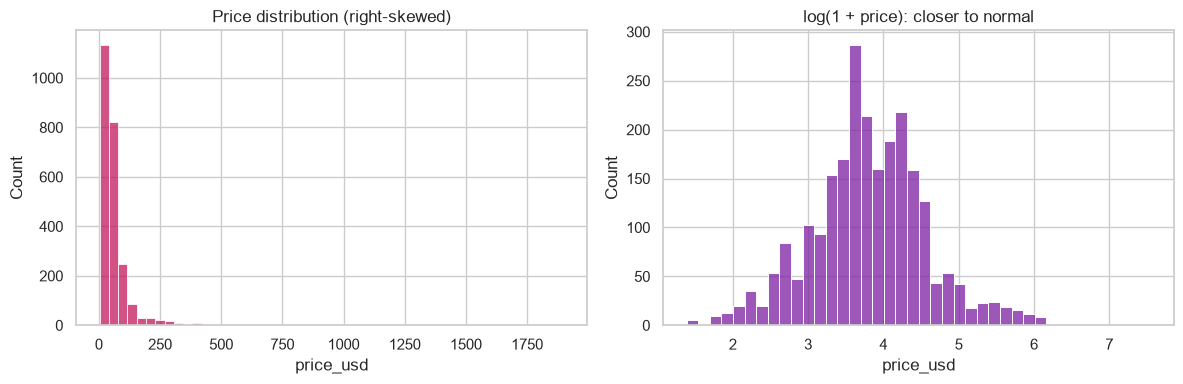

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\01_price_distribution.png


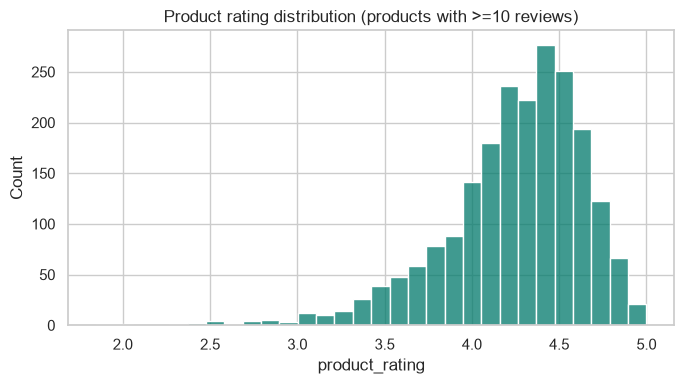

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\02_rating_distribution.png


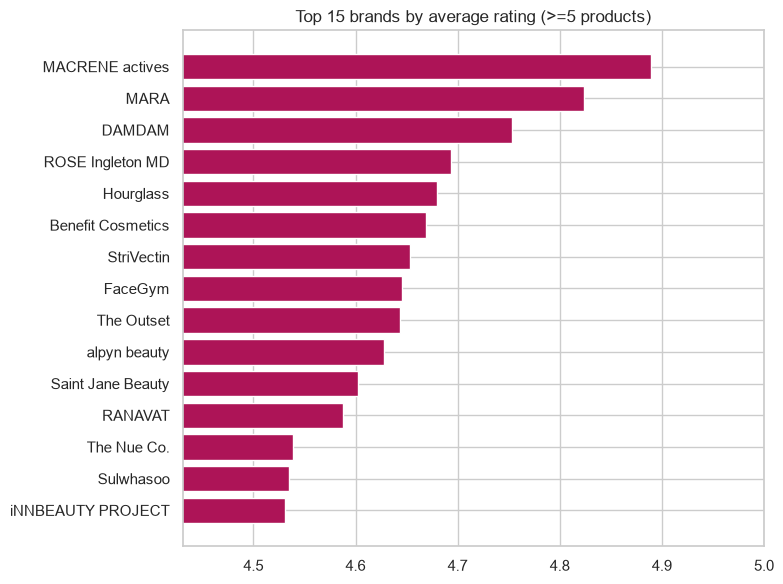

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\03_top_brands.png


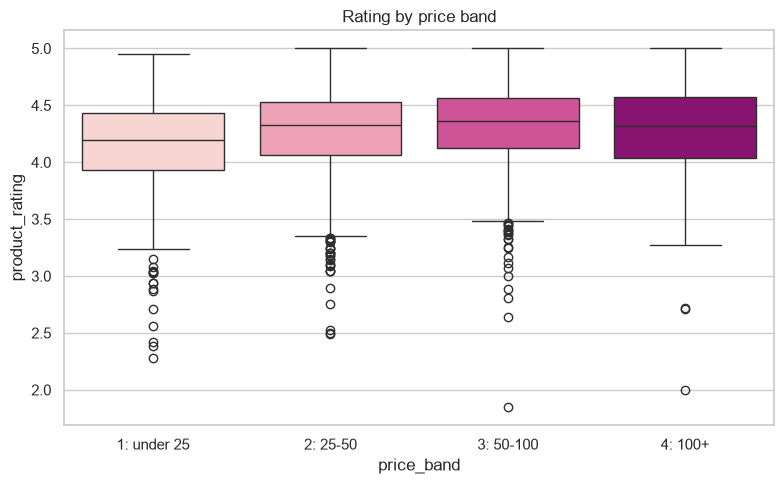

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\04_price_band_rating.png


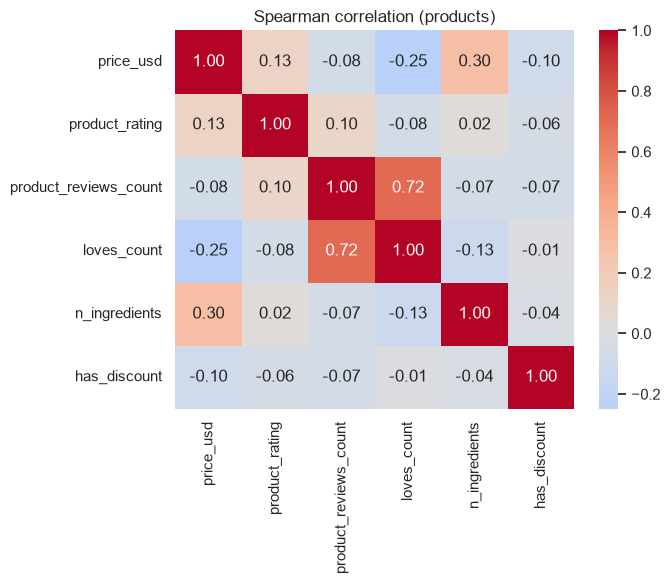

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\05_correlation_heatmap.png


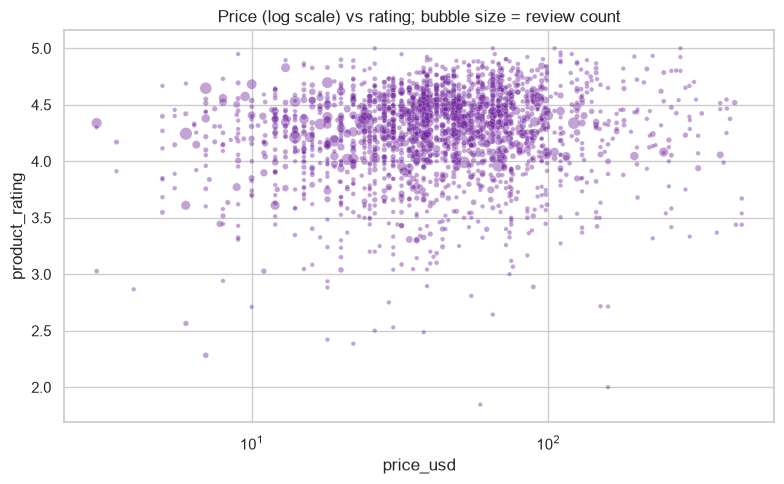

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\06_price_vs_rating.png


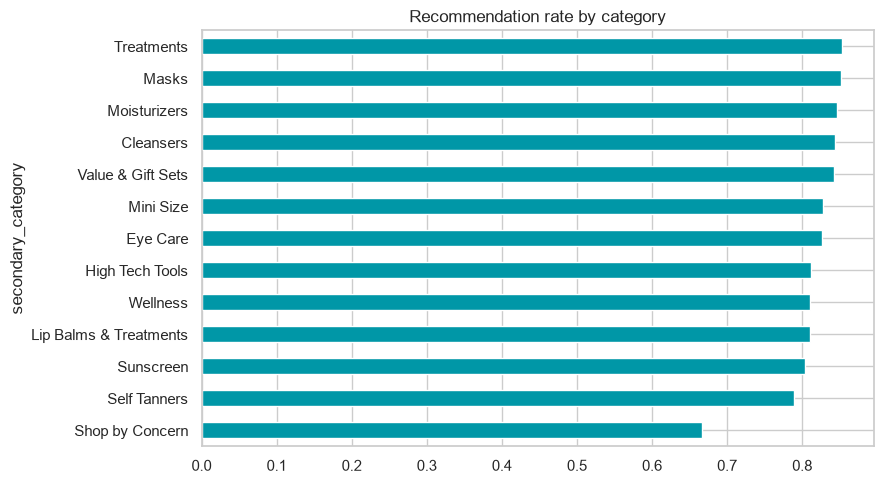

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\07_category_recommend.png


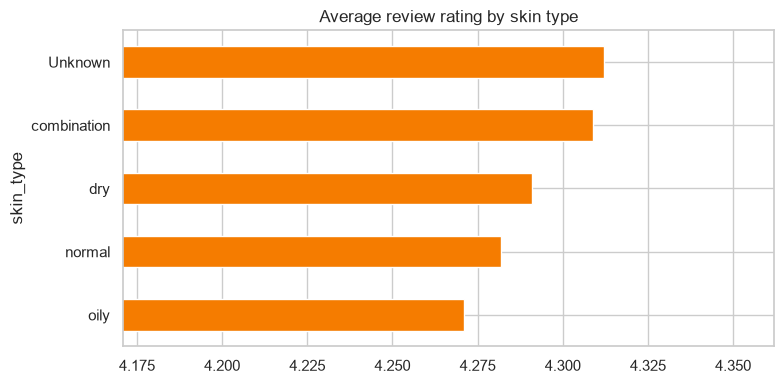

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\08_skin_type_rating.png


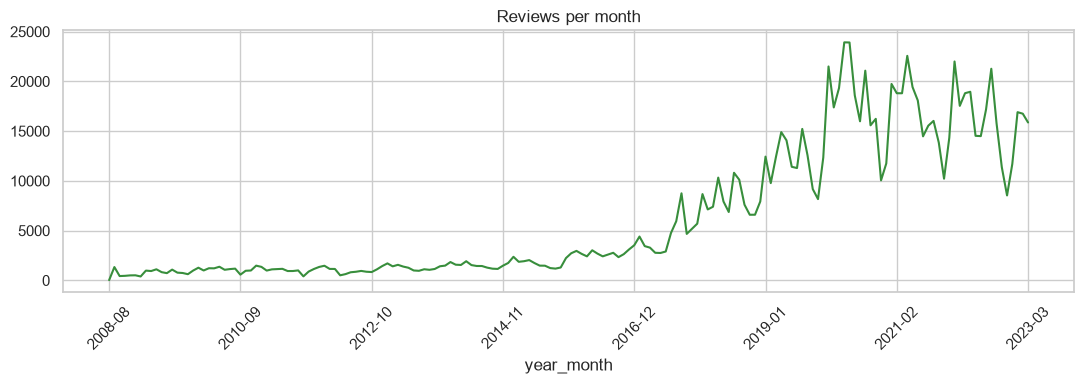

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\09_monthly_reviews.png


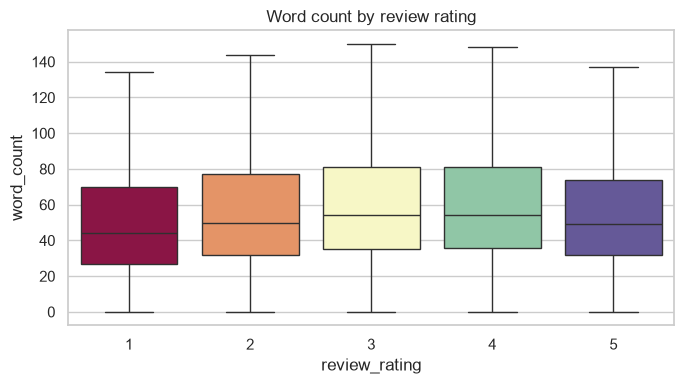

saved: C:\Users\Radhika Jawale\Downloads\outputs\charts\10_wordcount_rating.png


In [10]:
banner("4. VISUALISATION")
by_cat = summ("secondary_category")
by_skin = summ("skin_type")
monthly = rev.groupby("year_month").size()

# 1 price distribution
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(prod["price_usd"], bins=50, ax=ax[0], color="#c2185b")
ax[0].set_title("Price distribution (right-skewed)")
sns.histplot(np.log1p(prod["price_usd"]), bins=40, ax=ax[1], color="#7b1fa2")
ax[1].set_title("log(1 + price): closer to normal")
save_fig("01_price_distribution.png")

# 2 product rating distribution
plt.figure(figsize=(7, 4))
sns.histplot(rated["product_rating"], bins=30, color="#00796b")
plt.title("Product rating distribution (products with >=10 reviews)")
save_fig("02_rating_distribution.png")

# 3 top brands by avg rating
top_b = brand_perf.head(15).sort_values("avg_rating")
plt.figure(figsize=(8, 6))
plt.barh(top_b.index, top_b["avg_rating"], color="#ad1457")
plt.xlim(top_b["avg_rating"].min() - 0.1, 5)
plt.title("Top 15 brands by average rating (>=5 products)")
save_fig("03_top_brands.png")

# 4 price band vs rating
plt.figure(figsize=(8, 5))
order = sorted(rated["price_band"].unique())
sns.boxplot(data=rated, x="price_band", y="product_rating", order=order,
            hue="price_band", hue_order=order, palette="RdPu", legend=False)
plt.title("Rating by price band")
save_fig("04_price_band_rating.png")

# 5 correlation heatmap
corr_cols = ["price_usd", "product_rating", "product_reviews_count", "loves_count",
             "n_ingredients", "has_discount"]
plt.figure(figsize=(7, 6))
sns.heatmap(prod[corr_cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation (products)")
save_fig("05_correlation_heatmap.png")

# 6 price vs rating scatter
plt.figure(figsize=(8, 5))
sns.scatterplot(data=rated, x="price_usd", y="product_rating", alpha=0.4, size="product_reviews_count",
                sizes=(10, 200), legend=False, color="#6a1b9a")
plt.xscale("log")
plt.title("Price (log scale) vs rating; bubble size = review count")
save_fig("06_price_vs_rating.png")

# 7 category recommendation
fig, ax = plt.subplots(figsize=(9, 5))
by_cat["recommend_rate"].sort_values().plot.barh(ax=ax, color="#0097a7")
ax.set_title("Recommendation rate by category")
save_fig("07_category_recommend.png")

# 8 skin type satisfaction
fig, ax = plt.subplots(figsize=(8, 4))
by_skin["avg_rating"].sort_values().plot.barh(ax=ax, color="#f57c00")
ax.set_xlim(by_skin["avg_rating"].min() - 0.1, by_skin["avg_rating"].max() + 0.05)
ax.set_title("Average review rating by skin type")
save_fig("08_skin_type_rating.png")

# 9 monthly trend
plt.figure(figsize=(11, 4))
monthly.sort_index().plot(color="#388e3c")
plt.title("Reviews per month")
plt.xticks(rotation=45)
save_fig("09_monthly_reviews.png")

# 10 review length vs rating
plt.figure(figsize=(7, 4))
sns.boxplot(data=rev.sample(min(len(rev), 200000), random_state=1), x="review_rating", y="word_count",
            showfliers=False, hue="review_rating", palette="Spectral", legend=False)
plt.title("Word count by review rating")
save_fig("10_wordcount_rating.png")

## 5. SQL cross-check (same questions in SQL, compared with Pandas)

In [11]:
banner("5A. BUILD THE DATABASE")
con = sqlite3.connect(os.path.join(OUT_DIR, "sephora.db"))
prod.drop(columns=["ingredients"]).to_sql("products", con, if_exists="replace", index=False)
rev.drop(columns=["review_text", "review_title"]).to_sql(
    "reviews", con, if_exists="replace", index=False, chunksize=100000)
for t in ["reviews", "products"]:
    con.execute(f"CREATE INDEX IF NOT EXISTS ix_{t}_pid ON {t}(product_id)")
print("Tables:", pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)["name"].tolist())

# the five queries (also saved in sephora_queries.sql)
SQL = {}

SQL["q1_brand_performance"] = """
SELECT brand_name,
       COUNT(DISTINCT product_id)      AS product_count,
       ROUND(AVG(price_usd), 4)        AS avg_price,
       ROUND(AVG(product_rating), 4)   AS avg_rating,
       SUM(product_reviews_count)      AS total_reviews
FROM products
GROUP BY brand_name
HAVING COUNT(DISTINCT product_id) >= 5
ORDER BY avg_rating DESC
"""

SQL["q2_price_band_vs_rating"] = """
SELECT CASE WHEN price_usd < 25  THEN '1: under 25'
            WHEN price_usd < 50  THEN '2: 25-50'
            WHEN price_usd < 100 THEN '3: 50-100'
            ELSE '4: 100+' END         AS price_band,
       COUNT(*)                        AS product_count,
       ROUND(AVG(product_rating), 4)   AS avg_rating,
       ROUND(AVG(loves_count), 2)      AS avg_loves,
       SUM(product_reviews_count)      AS total_reviews
FROM products
GROUP BY price_band
ORDER BY price_band
"""

SQL["q3_category_satisfaction"] = """
SELECT secondary_category,
       COUNT(*)                        AS review_count,
       ROUND(AVG(review_rating), 4)    AS avg_review_rating,
       ROUND(AVG(is_recommended), 4)   AS recommend_rate
FROM reviews
GROUP BY secondary_category
ORDER BY recommend_rate DESC
"""

SQL["q4_top3_products_per_category"] = """
WITH ranked AS (
    SELECT secondary_category, product_id, product_name, brand_name,
           product_rating AS rating, product_reviews_count AS reviews,
           ROW_NUMBER() OVER (PARTITION BY secondary_category
                              ORDER BY product_rating DESC, product_reviews_count DESC, product_id
                             ) AS rank_in_category
    FROM products
    WHERE product_reviews_count >= 100
)
SELECT * FROM ranked
WHERE rank_in_category <= 3
ORDER BY secondary_category, rank_in_category
"""

SQL["q5_skin_type_segments"] = """
SELECT COALESCE(NULLIF(skin_type, ''), 'Unknown')   AS skin_type,
       COUNT(*)                                      AS review_count,
       ROUND(AVG(review_rating), 4)                  AS avg_review_rating,
       ROUND(AVG(is_recommended), 4)                 AS recommend_rate,
       ROUND(AVG(review_len), 2)                     AS avg_review_length
FROM reviews
GROUP BY COALESCE(NULLIF(skin_type, ''), 'Unknown')
ORDER BY review_count DESC
"""
print("Queries loaded:", list(SQL))


5A. BUILD THE DATABASE
Tables: ['products', 'reviews']
Queries loaded: ['q1_brand_performance', 'q2_price_band_vs_rating', 'q3_category_satisfaction', 'q4_top3_products_per_category', 'q5_skin_type_segments']


In [12]:
banner("5B. COMPARE SQL vs PANDAS")

def same(x, y, tol):
    """True if two columns match (numbers within tol, text exactly)."""
    if pd.api.types.is_numeric_dtype(x):
        return np.allclose(x.astype(float), y.astype(float), atol=tol, equal_nan=True)
    return (x.astype(str) == y.astype(str)).all()


def compare(name, sql_df, py_df, keys, tol=1e-3):
    a = sql_df.sort_values(keys).reset_index(drop=True)
    b = py_df[a.columns].sort_values(keys).reset_index(drop=True)
    if a.shape != b.shape:
        print(f"[{name}] SHAPE MISMATCH  sql={a.shape} python={b.shape}")
        return False
    bad = [c for c in a.columns if not same(a[c], b[c], tol)]
    for c in bad:
        print(f"[{name}] column '{c}' differs")
    print(f"[{name}] rows={len(a)} -> {'MATCH' if not bad else 'MISMATCH'}")
    return not bad


results = {}

# Q1 brand performance
sql1 = pd.read_sql(SQL["q1_brand_performance"], con)
py1 = (prod.groupby("brand_name")
       .agg(product_count=("product_id", "nunique"), avg_price=("price_usd", "mean"),
            avg_rating=("product_rating", "mean"), total_reviews=("product_reviews_count", "sum"))
       .query("product_count >= 5").round(4).reset_index())
results["Q1"] = compare("Q1 brand performance", sql1, py1, ["brand_name"])

# Q2 price band vs rating
sql2 = pd.read_sql(SQL["q2_price_band_vs_rating"], con)
py2 = (prod.groupby("price_band")
       .agg(product_count=("product_id", "size"), avg_rating=("product_rating", "mean"),
            avg_loves=("loves_count", "mean"), total_reviews=("product_reviews_count", "sum"))
       .round({"avg_rating": 4, "avg_loves": 2}).reset_index())
results["Q2"] = compare("Q2 price band", sql2, py2, ["price_band"])

# Q3 category satisfaction
sql3 = pd.read_sql(SQL["q3_category_satisfaction"], con)
py3 = (rev.groupby("secondary_category")
       .agg(review_count=("review_rating", "size"), avg_review_rating=("review_rating", "mean"),
            recommend_rate=("is_recommended", "mean")).round(4).reset_index())
results["Q3"] = compare("Q3 category satisfaction", sql3, py3, ["secondary_category"])

# Q4 top 3 per category
sql4 = pd.read_sql(SQL["q4_top3_products_per_category"], con)
tmp = (prod[prod["product_reviews_count"] >= 100]
       .rename(columns={"product_rating": "rating", "product_reviews_count": "reviews"})
       .sort_values(["secondary_category", "rating", "reviews", "product_id"],
                    ascending=[True, False, False, True], na_position="last").copy())
tmp["rank_in_category"] = tmp.groupby("secondary_category").cumcount() + 1
py4 = tmp[tmp["rank_in_category"] <= 3][
    ["secondary_category", "product_id", "product_name", "brand_name",
     "rating", "reviews", "rank_in_category"]].reset_index(drop=True)
results["Q4"] = compare("Q4 top-3 per category", sql4, py4, ["secondary_category", "rank_in_category"])

# Q5 skin type segments
sql5 = pd.read_sql(SQL["q5_skin_type_segments"], con)
py5 = (rev.assign(skin_type=rev["skin_type"].replace("", "Unknown").fillna("Unknown"))
          .groupby("skin_type")
          .agg(review_count=("review_rating", "size"), avg_review_rating=("review_rating", "mean"),
               recommend_rate=("is_recommended", "mean"), avg_review_length=("review_len", "mean"))
          .round({"avg_review_rating": 4, "recommend_rate": 4, "avg_review_length": 2})
          .reset_index())
results["Q5"] = compare("Q5 skin type", sql5, py5, ["skin_type"], tol=0.01)

print("\nALL QUERIES MATCH" if all(results.values()) else "\nSOME QUERIES DIFFER - see above")


5B. COMPARE SQL vs PANDAS
[Q1 brand performance] rows=104 -> MATCH
[Q2 price band] rows=4 -> MATCH
[Q3 category satisfaction] rows=13 -> MATCH
[Q4 top-3 per category] rows=36 -> MATCH
[Q5 skin type] rows=5 -> MATCH

ALL QUERIES MATCH


## 6. Project validation

In [13]:
banner("PROJECT VALIDATION")
checks = []

def check(name, ok, detail=""):
    checks.append((name, bool(ok)))
    print(f"{'PASS' if ok else 'FAIL'} | {name} {detail}")

# --- products ---
check("product_id is unique", prod["product_id"].is_unique)
check("only Skincare products", (prod["primary_category"] == "Skincare").all())
check("price_usd > 0", (prod["price_usd"] > 0).all())
check("product_rating between 1 and 5", prod["product_rating"].dropna().between(1, 5).all())
check("review / loves counts >= 0", (prod[["product_reviews_count", "loves_count"]] >= 0).all().all())
check("no 'nan' price band", (prod["price_band"] != "nan").all())

# --- reviews ---
check("review_rating between 1 and 5", rev["review_rating"].between(1, 5).all())
check("is_recommended only 0 / 1 / empty", rev["is_recommended"].dropna().isin([0, 1]).all())
check("every review belongs to a product", rev["product_id"].isin(prod["product_id"]).all())
check("no duplicate reviews",
      not rev.duplicated(["author_id", "product_id", "submission_time", "review_text"]).any())
check("no missing review dates", rev["submission_time"].notna().all())
check("no review dates in the future", rev["submission_time"].max() <= pd.Timestamp.today())
check("no duplicate columns after join", not any(c.endswith(("_x", "_y")) for c in rev.columns))

# --- row retention: cleaning must not throw away most of the data ---
kept = len(rev) / len(rev_raw)
check("at least 90% of raw reviews kept after cleaning", kept >= 0.90,
      f"-> {len(rev):,} of {len(rev_raw):,} kept ({kept:.1%})")

# --- raw dates are dd-mm-yyyy ---
ok_dd = pd.to_datetime(rev_raw["submission_time"], format="%d-%m-%Y", errors="coerce").notna().mean()
check("raw dates parse as dd-mm-yyyy", ok_dd > 0.99, f"-> {ok_dd:.1%} parse")

# --- SQL vs Pandas ---
check("SQL and Pandas results match (Q1-Q5)", all(results.values()))

failed = [n for n, ok in checks if not ok]
print(f"\n{len(checks) - len(failed)} of {len(checks)} checks passed.")
print("VALIDATION PASSED" if not failed else f"FIX THESE: {failed}")


PROJECT VALIDATION
PASS | product_id is unique 
PASS | only Skincare products 
PASS | price_usd > 0 
PASS | product_rating between 1 and 5 
PASS | review / loves counts >= 0 
PASS | no 'nan' price band 
PASS | review_rating between 1 and 5 
PASS | is_recommended only 0 / 1 / empty 
PASS | every review belongs to a product 
PASS | no duplicate reviews 
PASS | no missing review dates 
PASS | no review dates in the future 
PASS | no duplicate columns after join 
PASS | at least 90% of raw reviews kept after cleaning -> 1,093,888 of 1,094,411 kept (100.0%)
PASS | raw dates parse as dd-mm-yyyy -> 100.0% parse
PASS | SQL and Pandas results match (Q1-Q5) 

16 of 16 checks passed.
VALIDATION PASSED


In [14]:
import ast

def parse(x):
    try:
        return [i.strip().lower() for i in ast.literal_eval(x)]
    except Exception:
        return []

ing = prod[["product_id", "ingredients"]].copy()
ing["ingredient"] = ing["ingredients"].fillna("").apply(parse)
ing = ing.explode("ingredient").dropna(subset=["ingredient"])
ing = ing[ing["ingredient"] != ""]
ing["position"] = ing.groupby("product_id").cumcount() + 1   # 1 = first listed (highest amount)
ing = ing.drop_duplicates(["product_id", "ingredient"])

ing[["product_id", "ingredient", "position"]].to_csv(
    os.path.join(OUT_DIR, "ingredients_clean.csv"), index=False)
print(ing.shape, ing["ingredient"].nunique())
print(ing["ingredient"].value_counts().head(10))

(3601, 4) 3030
ingredient
step 1:                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

In [15]:
prod.drop(columns=["ingredients"]).to_csv(os.path.join(OUT_DIR, "products_clean.csv"), index=False)
print("products_clean.csv re-saved with weighted_rating and value_score")

products_clean.csv re-saved with weighted_rating and value_score
